# Performing data cleaning
Checking for missing values and outliers

In [1]:
import pandas as pd

filename = r"..\data\winequality-red.csv"

df = pd.read_csv(filename)

In [2]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [9]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [4]:
nulls = df.isnull()

for col in df.columns.to_list():
    print(f"Column {col} has {sum(nulls[col])} null values")

Column fixed acidity has 0 null values
Column volatile acidity has 0 null values
Column citric acid has 0 null values
Column residual sugar has 0 null values
Column chlorides has 0 null values
Column free sulfur dioxide has 0 null values
Column total sulfur dioxide has 0 null values
Column density has 0 null values
Column pH has 0 null values
Column sulphates has 0 null values
Column alcohol has 0 null values
Column quality has 0 null values


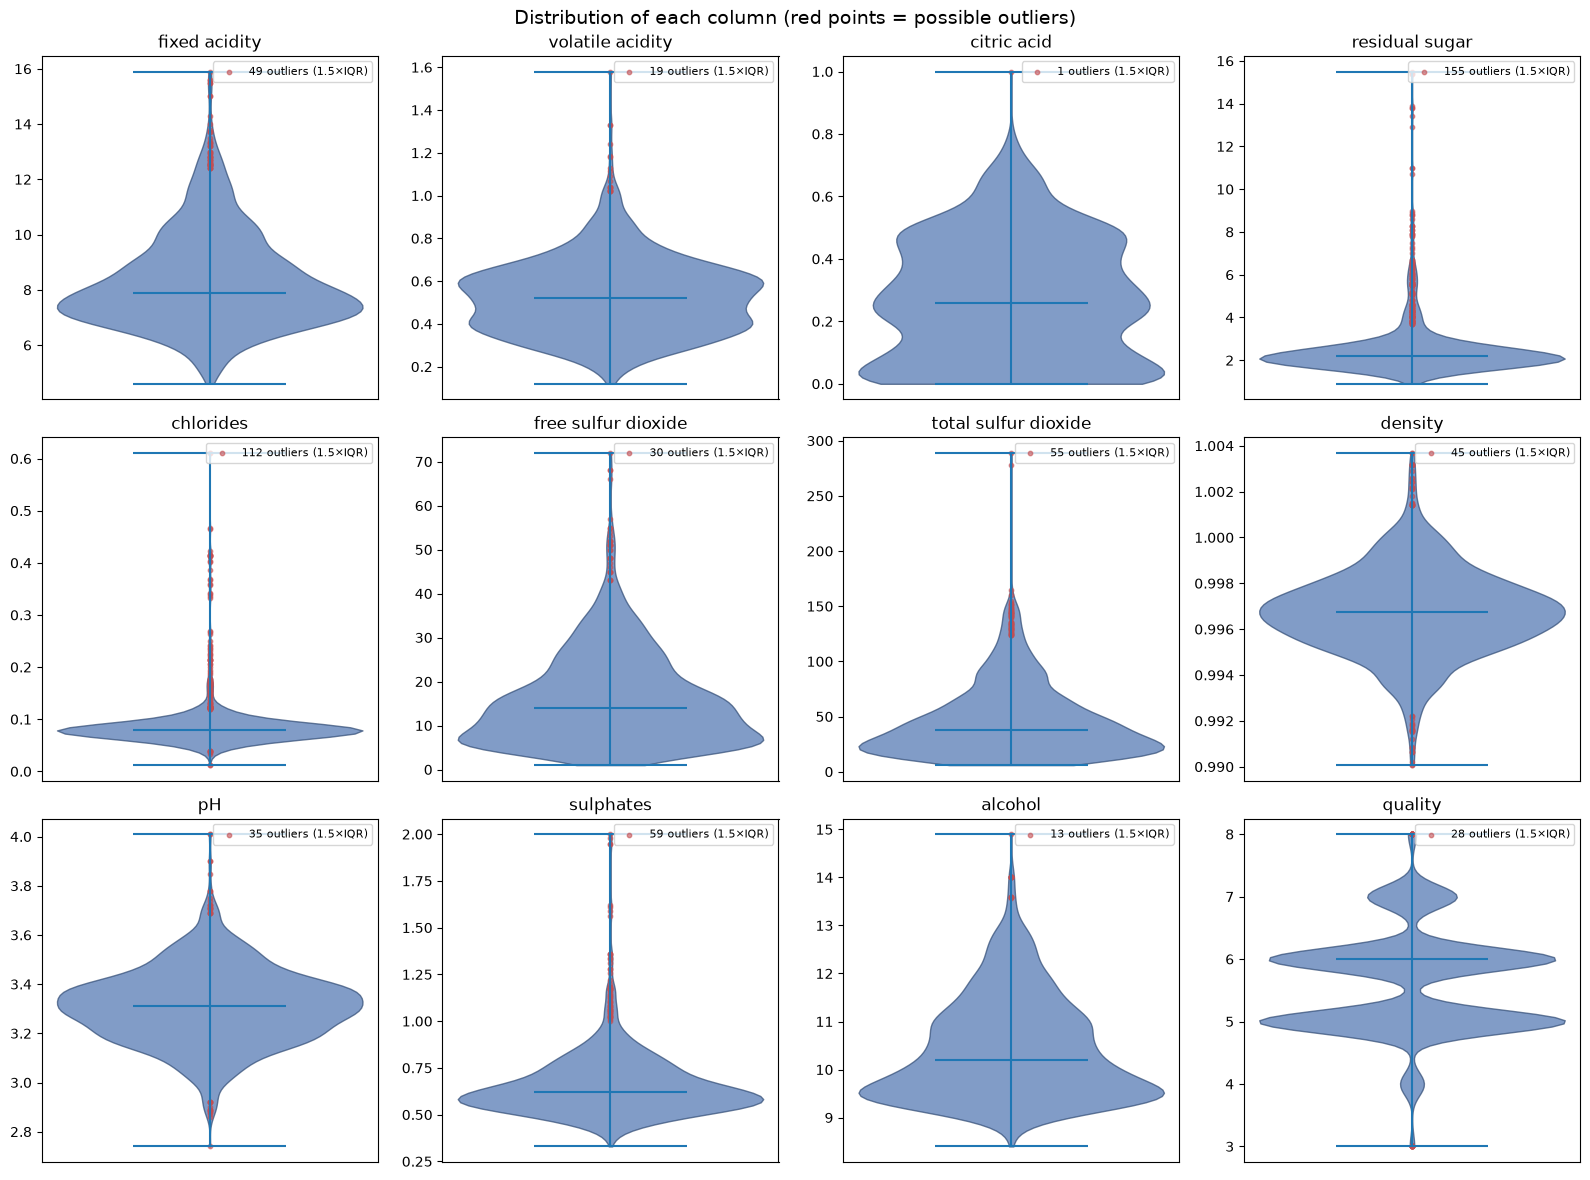

In [5]:
import math
import matplotlib.pyplot as plt

# Columns have very different scales, so give each its own subplot/axis
cols = df.columns.to_list()
ncols = 4
nrows = math.ceil(len(cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    parts = ax.violinplot(df[col], showmedians=True, showextrema=True)
    for body in parts["bodies"]:
        body.set_facecolor("#4C72B0")
        body.set_edgecolor("#2F4A73")
        body.set_alpha(0.7)

    # Overlay points beyond 1.5 * IQR to highlight possible outliers
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = df[col][(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    ax.scatter([1] * len(outliers), outliers, color="#C44E52", s=10, alpha=0.6,
               label=f"{len(outliers)} outliers (1.5×IQR)")

    ax.set_title(col)
    ax.set_xticks([])
    ax.legend(loc="upper right", fontsize=8)

# Hide any unused subplots
for ax in axes[len(cols):]:
    ax.set_visible(False)

fig.suptitle("Distribution of each column (red points = possible outliers)", fontsize=14)
fig.tight_layout()
plt.show()

In [7]:
# Tukey's rule: a value is an outlier if it falls below Q1 - 1.5*IQR or above Q3 + 1.5*IQR.
# Bounds are computed on the original data for every column, and a row is removed
# if it is an outlier in any column.
outlier_mask = pd.Series(False, index=df.index)

for col in df.columns.drop("quality").to_list():
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    col_outliers = (df[col] < lower) | (df[col] > upper)
    outlier_mask |= col_outliers
    print(f"Column {col}: {col_outliers.sum()} outliers (bounds {lower:.4f} to {upper:.4f})")

df_clean = df[~outlier_mask].reset_index(drop=True)

total_removed = len(df) - len(df_clean)
print(f"\nTotal rows removed: {total_removed} of {len(df)} ({total_removed / len(df):.1%})")
print(f"Rows remaining: {len(df_clean)}")

Column fixed acidity: 49 outliers (bounds 3.9500 to 12.3500)
Column volatile acidity: 19 outliers (bounds 0.0150 to 1.0150)
Column citric acid: 1 outliers (bounds -0.4050 to 0.9150)
Column residual sugar: 155 outliers (bounds 0.8500 to 3.6500)
Column chlorides: 112 outliers (bounds 0.0400 to 0.1200)
Column free sulfur dioxide: 30 outliers (bounds -14.0000 to 42.0000)
Column total sulfur dioxide: 55 outliers (bounds -38.0000 to 122.0000)
Column density: 45 outliers (bounds 0.9922 to 1.0012)
Column pH: 35 outliers (bounds 2.9250 to 3.6850)
Column sulphates: 59 outliers (bounds 0.2800 to 1.0000)
Column alcohol: 13 outliers (bounds 7.1000 to 13.5000)

Total rows removed: 405 of 1599 (25.3%)
Rows remaining: 1194


In [8]:
df_clean.to_csv("../data/cleaned_winequality_red.csv")